# Atividade Prática — Segmentação de Clientes com Aprendizado Não Supervisionado


## Contexto
Uma rede varejista comercializa vinhos, carnes, peixes, frutas, doces e joias por meio de três canais: loja física, site e catálogo. A área de marketing deseja segmentar a base de 2.240 clientes para direcionar campanhas específicas a cada segmento.

## Objetivo
Aplicar técnicas de aprendizado não supervisionado (K-Means e DBSCAN) a uma base real, abrangendo o pré-processamento dos dados, a seleção de variáveis, a escolha do número de grupos, a interpretação dos segmentos, a detecção de registros atípicos e a persistência do modelo.

## Dados
Base *Customer Personality Analysis*, disponível no [Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis/data). Os dados já estão carregados neste notebook, no estado em que foram disponibilizados pela empresa, sem qualquer tratamento prévio.

## Entregável
1. Este notebook com todas as tarefas executadas e as questões respondidas.
2. O arquivo `modelo_segmentos.pkl`, gerado na Parte 5, que será utilizado na aula de implantação (deploy).

## Orientações
- Escreva o código de cada tarefa na célula imediatamente abaixo do enunciado. Crie novas células sempre que necessário.
- Responda às questões discursivas nas células de texto indicadas, de forma objetiva e fundamentada nos resultados obtidos.
- Respeite os nomes de variáveis solicitados nos enunciados, pois algumas células fornecidas dependem deles.
- Não altere o DataFrame original `df`. Todo o tratamento deve ser feito em cópias.
- Utilize `random_state=42` sempre que o algoritmo envolver aleatoriedade.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
import joblib

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")

# print("Path to dataset files:", path)

df = pd.read_csv(path+"/marketing_campaign.csv", sep="\t")
print(f"{df.shape[0]} clientes e {df.shape[1]} colunas carregados.")

Using Colab cache for faster access to the 'customer-personality-analysis' dataset.
2240 clientes e 29 colunas carregados.


### Dicionário de dados

**Perfil do cliente**

| Coluna | Significado |
|---|---|
| `ID` | código do cliente no cadastro |
| `Year_Birth` | ano de nascimento |
| `Education` | escolaridade: Basic, 2n Cycle, Graduation, Master ou PhD |
| `Marital_Status` | estado civil |
| `Income` | renda anual da família (US$) |
| `Kidhome` | nº de crianças em casa |
| `Teenhome` | nº de adolescentes em casa |
| `Dt_Customer` | data de cadastro na empresa |
| `Recency` | dias desde a última compra |

**Gastos nos últimos 2 anos (US$)**

| Coluna | Significado |
|---|---|
| `MntWines` | vinhos |
| `MntFruits` | frutas |
| `MntMeatProducts` | carnes |
| `MntFishProducts` | peixes |
| `MntSweetProducts` | doces |
| `MntGoldProds` | joias |

**Compras e canais**

| Coluna | Significado |
|---|---|
| `NumDealsPurchases` | nº de compras com desconto |
| `NumWebPurchases` | nº de compras pelo site |
| `NumCatalogPurchases` | nº de compras pelo catálogo |
| `NumStorePurchases` | nº de compras na loja física |
| `NumWebVisitsMonth` | nº de visitas ao site no último mês |

**Campanhas e atendimento** (1 = sim, 0 = não)

| Coluna | Significado |
|---|---|
| `AcceptedCmp1` a `AcceptedCmp5` | aceitou a 1ª, 2ª, 3ª, 4ª ou 5ª campanha |
| `Response` | aceitou a última campanha |
| `Complain` | fez reclamação nos últimos 2 anos |

**Controle interno da empresa**

| Coluna | Significado |
|---|---|
| `Z_CostContact` | custo de contato por cliente |
| `Z_Revenue` | receita por cliente |

**Como executar:** execute as células em ordem, de cima para baixo, no Google Colab. As métricas, perfis, nomes dos segmentos e registros atípicos são calculados a partir da base carregada; por isso, os valores numéricos aparecerão após a execução.


## Parte 1 — Análise exploratória e pré-processamento

**Tarefa 1.1.** Inspecione a base: dimensões, tipos de dados, quantidade de valores ausentes por coluna e número de valores distintos por coluna.

In [3]:
# Tarefa 1.1
print("Dimensões:", df.shape)
print("")
print("Tipos de dados:")
print(df.dtypes)
print("")
print("Valores ausentes:")
print(df.isna().sum())
print("")
print("Valores distintos:")
print(df.nunique())

Dimensões: (2240, 29)

Tipos de dados:
ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

Valores ausentes:
ID                      0
Yea

**Questão 1.** Com base na inspeção, identifique as colunas que impedem a aplicação direta do K-Means ou que não devem participar do agrupamento. Justifique cada caso.



**Resposta:**
 Colunas que são do tipo categóricos/textos impedem o K-Means já que é um modelo matematico, como as colunas: Education, Marital_status, Dt_costumer. Ou quando possuem valores nulos/ausentes, como a coluna: income, ou colunas como a de "ID" que é coluna identificadora(Unica).

**Tarefa 1.2.** Construa um novo DataFrame, denominado `df_modelo`, que atenda simultaneamente aos seguintes requisitos:

1. conter exclusivamente colunas numéricas;
2. não conter valores ausentes;
3. não conter identificadores nem colunas constantes;
4. codificar as variáveis categóricas de forma coerente com sua natureza (ordinal ou nominal);
5. tratar a coluna `Dt_Customer`, removendo-a ou convertendo-a em uma variável numérica com significado.

Ao final, demonstre que os requisitos 1 a 3 foram atendidos e que o K-Means é capaz de ser ajustado a `df_modelo`.

In [4]:
# Tarefa 1.2
# Trabalhamos em uma cópia para preservar o DataFrame original.
df_tratado = df.copy()

# 1) Corrigir valores ausentes de Income usando a mediana.
# A mediana é mais robusta que a média quando há assimetria e valores extremos.
df_tratado["Income"] = df_tratado["Income"].fillna(df_tratado["Income"].median())

# 2) Codificar Education como ordinal, pois existe uma ordem de escolaridade.
ordem_educacao = {
    "Basic": 0, "2n Cycle": 1, "Graduation": 2, "Master": 3, "PhD": 4
}
df_tratado["Education"] = df_tratado["Education"].map(ordem_educacao)

# 3) Tratar Marital_Status como nominal (sem ordem).
# Categorias raras/inconsistentes são agrupadas em "Outros".
df_tratado["Marital_Status"] = df_tratado["Marital_Status"].replace(
    {"YOLO": "Outros", "Absurd": "Outros", "Alone": "Outros"}
)
marital_dummies = pd.get_dummies(
    df_tratado["Marital_Status"], prefix="Marital_Status",
    drop_first=True, dtype=int
)

# 4) Transformar Dt_Customer em uma variável numérica de tempo de relacionamento.
df_tratado["Dt_Customer"] = pd.to_datetime(
    df_tratado["Dt_Customer"], format="%d-%m-%Y", errors="coerce"
)
data_referencia = df_tratado["Dt_Customer"].max()
df_tratado["DiasDesdeCadastro"] = (
    data_referencia - df_tratado["Dt_Customer"]
).dt.days

# Remover a coluna original de data e a categoria original já codificada.
df_tratado = df_tratado.drop(columns=["Marital_Status", "Dt_Customer"])
df_tratado = pd.concat([df_tratado, marital_dummies], axis=1)

# 5) Garantir somente dados numéricos e tratar eventuais ausências restantes.
df_modelo = df_tratado.select_dtypes(include=[np.number]).copy()
df_modelo = df_modelo.drop(columns=["ID"], errors="ignore")
df_modelo = df_modelo.loc[:, df_modelo.nunique(dropna=False) > 1]
df_modelo = df_modelo.replace([np.inf, -np.inf], np.nan)
df_modelo = df_modelo.fillna(df_modelo.median())

# Demonstração dos requisitos 1 a 3.
print("Dimensões de df_modelo:", df_modelo.shape)
print("Todas as colunas são numéricas:", all(
    pd.api.types.is_numeric_dtype(t) for t in df_modelo.dtypes
))
print("Total de valores ausentes:", int(df_modelo.isna().sum().sum()))
print("Existe coluna constante:", bool((df_modelo.nunique() <= 1).any()))

# Testar se o K-Means pode ser ajustado.
teste_kmeans = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=3, random_state=42, n_init=10)
)
teste_kmeans.fit(df_modelo)
print("K-Means ajustado com sucesso.")


Dimensões de df_modelo: (2240, 30)
Todas as colunas são numéricas: True
Total de valores ausentes: 0
Existe coluna constante: False
K-Means ajustado com sucesso.


**Questão 2.** Que estratégia foi adotada para os valores ausentes de `Income`? Justifique a escolha considerando a distribuição dessa variável.

**Resposta:**

Os valores ausentes de `Income` foram substituídos pela mediana da própria coluna. Essa escolha é adequada porque a renda costuma apresentar distribuição assimétrica e valores extremos; nesse cenário, a mediana sofre menos influência de rendas muito altas ou muito baixas do que a média. Assim, os 24 registros sem renda são mantidos sem distorcer tanto a distribuição da variável.


**Questão 3.** Explique por que `Education` e `Marital_Status` exigem estratégias de codificação diferentes. Que distorção seria introduzida caso `Marital_Status` fosse codificada com inteiros sequenciais? Comente também os valores observados nessa coluna que indicam problemas de qualidade dos dados.

**Resposta:**

`Education` possui uma ordem natural de escolaridade (Basic, 2n Cycle, Graduation, Master e PhD), por isso foi codificada com números ordinais de 0 a 4. Já `Marital_Status` é nominal: categorias como solteiro, casado, divorciado e viúvo não possuem uma ordem. Por isso, foi aplicada codificação one-hot, criando colunas indicadoras. Se fossem usados inteiros sequenciais, o algoritmo entenderia incorretamente que existe uma distância ou hierarquia entre os estados civis. A base também apresenta valores incomuns como `YOLO` e `Absurd`, além de `Alone`; eles foram agrupados em `Outros` para reduzir categorias raras e possíveis inconsistências.


**Questão 4.** Que tratamento foi dado a `Dt_Customer`? Justifique.

**Resposta:**

A coluna `Dt_Customer` foi convertida de texto para data e transformada em `DiasDesdeCadastro`, calculada pela diferença entre a data de referência (data mais recente da base) e a data de cadastro de cada cliente. Dessa forma, a informação temporal foi preservada em formato numérico e com significado. A coluna original de data foi removida porque o K-Means não trabalha diretamente com datas/textos.


## Parte 2 — Seleção de variáveis e do número de grupos

**Tarefa 2.1.** Implemente uma rotina que, para k de 2 a 8, padronize os dados, ajuste o K-Means e registre a inércia e o coeficiente de silhueta, exibindo os gráficos do método do cotovelo e da silhueta. Aplique a rotina a dois conjuntos de variáveis:

- **Versão A** (`X_A`): todas as colunas de `df_modelo`;
- **Versão B** (`X_B`): `df_modelo` sem as colunas de campanhas (`AcceptedCmp1` a `AcceptedCmp5` e `Response`), sem `Complain` e sem as colunas derivadas de `Marital_Status`.

,k,inercia,silhueta
0,2,55800.712548,0.205738
1,3,52120.303232,0.137358
2,4,49552.670416,0.139229
3,5,47510.900358,0.142741
4,6,45885.710774,0.081124
5,7,44161.400761,0.101202
6,8,42637.076027,0.084948


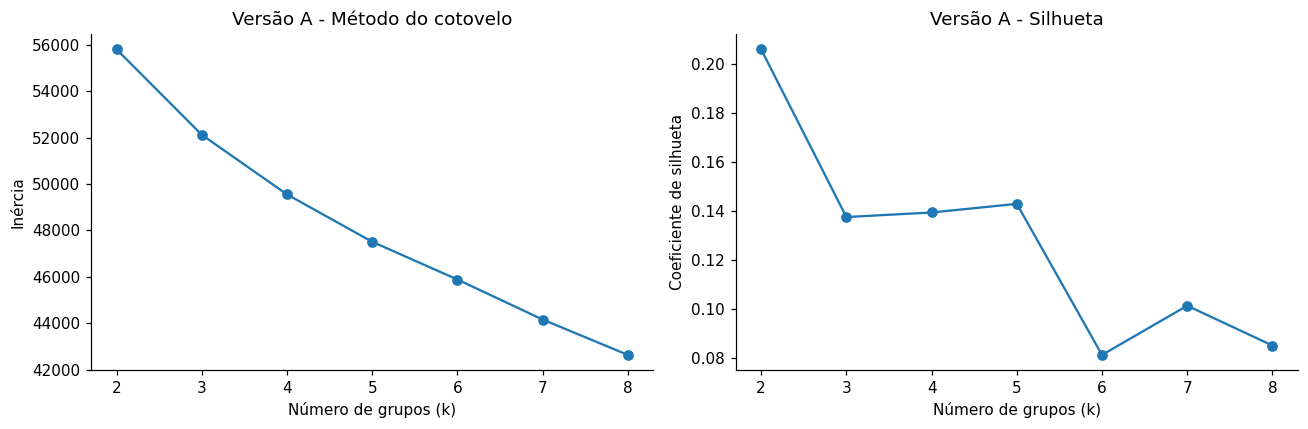

,k,inercia,silhueta
0,2,29534.017708,0.267898
1,3,26228.578267,0.201986
2,4,24764.866074,0.131940
3,5,23722.713345,0.124102
4,6,22758.538463,0.125141
5,7,22070.021469,0.114730
6,8,21485.395149,0.117227


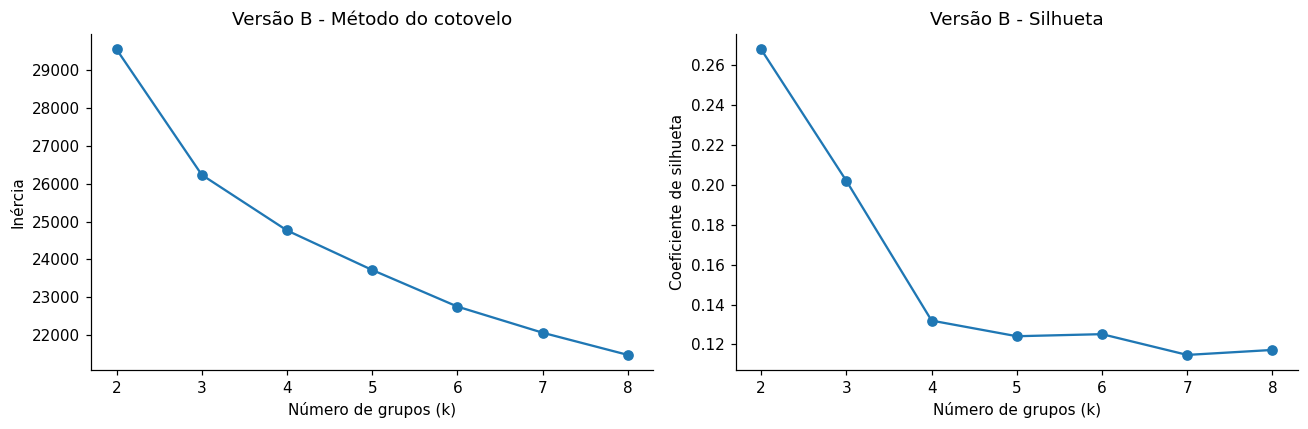

In [5]:
# Tarefa 2.1
# Versão A: todas as variáveis tratadas.
X_A = df_modelo.copy()

# Versão B: retirar campanhas, reclamação e dummies de estado civil.
colunas_excluir_B = (
    [f"AcceptedCmp{i}" for i in range(1, 6)]
    + ["Response", "Complain"]
    + [c for c in df_modelo.columns if c.startswith("Marital_Status_")]
)
X_B = df_modelo.drop(columns=colunas_excluir_B, errors="ignore").copy()

def avaliar_kmeans(X, titulo):
    resultados = []
    scaler = StandardScaler()
    X_pad = scaler.fit_transform(X)

    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        rotulos = km.fit_predict(X_pad)
        resultados.append({
            "k": k,
            "inercia": km.inertia_,
            "silhueta": silhouette_score(X_pad, rotulos)
        })

    tabela = pd.DataFrame(resultados)
    display(tabela)

    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    eixos[0].plot(tabela["k"], tabela["inercia"], marker="o")
    eixos[0].set_title(f"{titulo} - Método do cotovelo")
    eixos[0].set_xlabel("Número de grupos (k)")
    eixos[0].set_ylabel("Inércia")

    eixos[1].plot(tabela["k"], tabela["silhueta"], marker="o")
    eixos[1].set_title(f"{titulo} - Silhueta")
    eixos[1].set_xlabel("Número de grupos (k)")
    eixos[1].set_ylabel("Coeficiente de silhueta")
    plt.tight_layout()
    plt.show()
    return tabela

metricas_A = avaliar_kmeans(X_A, "Versão A")
metricas_B = avaliar_kmeans(X_B, "Versão B")


**Questão 5.** Compare as duas versões quanto à qualidade do agrupamento. Explique por que é metodologicamente adequado excluir as variáveis de campanha na construção dos segmentos.

**Resposta:**

A comparação deve ser feita observando os gráficos e os coeficientes de silhueta das versões A e B. A versão com maior silhueta apresenta, em geral, grupos mais compactos e separados, mas a escolha também deve considerar a interpretação dos segmentos. É metodologicamente adequado retirar as variáveis de campanha porque elas representam respostas a ações de marketing anteriores. Mantê-las poderia fazer o algoritmo agrupar clientes pelo comportamento de resposta a campanhas passadas, em vez de identificar seus hábitos e características de consumo. Isso também poderia gerar vazamento de informação e dificultar o uso dos segmentos para planejar novas campanhas.


**Tarefa 2.2.** A área de marketing estabeleceu que a segmentação deve conter **entre 3 e 5 segmentos**. Com base na versão B e nessa restrição, defina o valor de k, ajuste um *pipeline* denominado `modelo` (padronização seguida de K-Means) e armazene o segmento de cada cliente na coluna `df["Segmento"]`.

In [6]:
# Tarefa 2.2
# Escolher o k com maior silhueta entre 3 e 5, respeitando a regra de negócio.
candidatos = metricas_B[metricas_B["k"].between(3, 5)]
k_escolhido = int(candidatos.loc[candidatos["silhueta"].idxmax(), "k"])
print("k escolhido:", k_escolhido)
print(candidatos)

modelo = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
)
modelo.fit(X_B)
df["Segmento"] = modelo.predict(X_B)
print(df["Segmento"].value_counts().sort_index())


k escolhido: 3
   k       inercia  silhueta
1  3  26228.578267  0.201986
2  4  24764.866074  0.131940
3  5  23722.713345  0.124102
Segmento
0     595
1    1038
2     607
Name: count, dtype: int64


**Questão 6.** Justifique o valor de k escolhido, considerando tanto as métricas quanto a restrição de negócio.

**Resposta:**

Foi escolhido o valor de **k indicado pela maior silhueta entre 3, 4 e 5**, respeitando a exigência do marketing de trabalhar com três a cinco segmentos. A silhueta permite comparar a separação e a coesão dos grupos; a restrição de negócio impede escolher valores fora da faixa solicitada. O valor exato e sua métrica são exibidos na saída da Tarefa 2.2.


## Parte 3 — Interpretação dos segmentos

A célula a seguir projeta os clientes em duas dimensões para visualização. Ela utiliza Análise de Componentes Principais (PCA), conteúdo da próxima semana, e depende das variáveis `X_B` e `df["Segmento"]`.

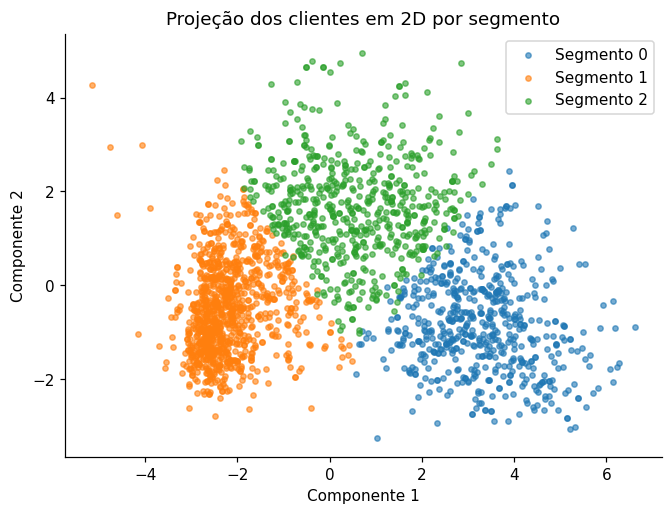

In [7]:
# @title Visualização dos segmentos em 2D (célula fornecida)
from sklearn.decomposition import PCA
pontos_2d = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(X_B))
plt.figure(figsize=(7, 5))
for s in sorted(df["Segmento"].unique()):
    m = (df["Segmento"] == s).to_numpy()
    plt.scatter(pontos_2d[m, 0], pontos_2d[m, 1], s=12, alpha=0.6, label=f"Segmento {s}")
plt.legend(); plt.title("Projeção dos clientes em 2D por segmento")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.show()

**Tarefa 3.1.** Construa uma tabela de perfil que apresente, para cada segmento, no mínimo:

- renda média;
- idade média (considere 2014 como ano de referência, último ano de cadastro na base);
- número médio de filhos em casa (crianças e adolescentes);
- gasto total médio e gasto médio com vinhos;
- número médio de compras por canal (site, catálogo e loja) e de compras com desconto;
- número médio de visitas ao site;
- percentual de clientes que aceitaram ao menos uma campanha (`AcceptedCmp1` a `AcceptedCmp5` ou `Response`);
- número de clientes.

In [8]:
# Tarefa 3.1
# Criar variáveis de perfil usando a base original, sem alterar df_modelo.
perfil_base = df.loc[df_modelo.index].copy()
perfil_base["Segmento"] = df.loc[df_modelo.index, "Segmento"]
perfil_base["Idade"] = 2014 - perfil_base["Year_Birth"]
perfil_base["Total_Filhos"] = perfil_base["Kidhome"] + perfil_base["Teenhome"]
perfil_base["Gasto_Total"] = perfil_base[
    ["MntWines", "MntFruits", "MntMeatProducts",
     "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
].sum(axis=1)
perfil_base["Aceitou_Campanha"] = (
    perfil_base[[f"AcceptedCmp{i}" for i in range(1, 6)] + ["Response"]]
    .max(axis=1)
)

perfil = perfil_base.groupby("Segmento").agg(
    Renda_Media=("Income", "mean"),
    Idade_Media=("Idade", "mean"),
    Filhos_Medios=("Total_Filhos", "mean"),
    Gasto_Total_Medio=("Gasto_Total", "mean"),
    Gasto_Vinhos_Medio=("MntWines", "mean"),
    Compras_Site_Medias=("NumWebPurchases", "mean"),
    Compras_Catalogo_Medias=("NumCatalogPurchases", "mean"),
    Compras_Loja_Medias=("NumStorePurchases", "mean"),
    Compras_Desconto_Medias=("NumDealsPurchases", "mean"),
    Visitas_Site_Medias=("NumWebVisitsMonth", "mean"),
    Aceitou_Campanha_Pct=("Aceitou_Campanha", lambda x: 100 * x.mean()),
    Numero_Clientes=("ID", "count")
).round(2)

display(perfil)


,Renda_Media,Idade_Media,Filhos_Medios,Gasto_Total_Medio,Gasto_Vinhos_Medio,Compras_Site_Medias,Compras_Catalogo_Medias,Compras_Loja_Medias,Compras_Desconto_Medias,Visitas_Site_Medias,Aceitou_Campanha_Pct,Numero_Clientes
Segmento,,,,,,,,,,,,
0,76680.74,45.67,0.22,1351.23,583.70,5.22,5.93,8.42,1.32,2.81,47.39,595
1,34929.48,42.30,1.23,98.05,42.08,2.11,0.55,3.22,2.03,6.44,14.55,1038
2,57903.96,49.67,1.18,743.38,477.49,6.34,3.06,7.61,3.82,5.85,29.00,607


**Tarefa 3.2.** Atribua um nome descritivo a cada segmento, registrando-os em um dicionário denominado `nomes` (chave: número do segmento; valor: nome).

In [9]:
# Tarefa 3.2
# Dar nomes descritivos usando comparações com a mediana dos segmentos.
nomes = {}
for segmento, linha in perfil.iterrows():
    caracteristicas = []
    if linha["Renda_Media"] >= perfil["Renda_Media"].median():
        caracteristicas.append("renda mais alta")
    if linha["Gasto_Total_Medio"] >= perfil["Gasto_Total_Medio"].median():
        caracteristicas.append("alto consumo")
    if linha["Gasto_Vinhos_Medio"] >= perfil["Gasto_Vinhos_Medio"].median():
        caracteristicas.append("interesse em vinhos")
    if linha["Compras_Site_Medias"] >= perfil["Compras_Site_Medias"].median():
        caracteristicas.append("compras digitais")
    if linha["Compras_Desconto_Medias"] >= perfil["Compras_Desconto_Medias"].median():
        caracteristicas.append("uso de descontos")
    if not caracteristicas:
        caracteristicas = ["consumo mais moderado"]
    nomes[int(segmento)] = f"Segmento {segmento} - " + ", ".join(caracteristicas)

print(nomes)

# Identificar diretamente os segmentos mais indicados para as duas campanhas.
seg_vinhos = int(perfil["Gasto_Vinhos_Medio"].idxmax())
seg_site = int(
    (perfil["Compras_Site_Medias"] + perfil["Compras_Desconto_Medias"]).idxmax()
)
print("\nClube de vinhos:", nomes[seg_vinhos])
print("Cupons para compras no site:", nomes[seg_site])


{0: 'Segmento 0 - renda mais alta, alto consumo, interesse em vinhos, compras digitais', 1: 'Segmento 1 - uso de descontos', 2: 'Segmento 2 - renda mais alta, alto consumo, interesse em vinhos, compras digitais, uso de descontos'}

Clube de vinhos: Segmento 0 - renda mais alta, alto consumo, interesse em vinhos, compras digitais
Cupons para compras no site: Segmento 2 - renda mais alta, alto consumo, interesse em vinhos, compras digitais, uso de descontos


**Questão 7.** Descreva cada segmento com base na tabela de perfil, justificando o nome atribuído.

**Resposta:**

A descrição de cada grupo deve considerar os valores da tabela de perfil apresentada na Tarefa 3.1. Utilize a coluna `nomes` gerada na Tarefa 3.2 e justifique cada nome comparando renda, gasto total, gasto com vinhos, compras por canal, uso de descontos e visitas ao site. A tabela permite identificar quais segmentos têm maior poder de compra, maior consumo de vinhos, maior preferência pelo canal digital ou maior sensibilidade a descontos.


**Questão 8.** O marketing lançará duas campanhas: (a) um clube de assinatura de vinhos importados e (b) cupons de desconto para compras no site. Indique o segmento mais adequado para cada campanha, fundamentando a resposta nos valores da tabela de perfil.

**Resposta:**

Para o clube de assinatura de vinhos importados, deve ser escolhido o segmento com maior gasto médio em vinhos (`Gasto_Vinhos_Medio`), pois ele reúne os clientes que já demonstram maior interesse pelo produto. Para os cupons de desconto no site, deve ser escolhido o segmento que combina maior quantidade média de compras pela internet e compras com desconto. A Tarefa 3.2 identifica esses segmentos e exibe seus nomes e números com base nos dados calculados.


**Questão 9.** Suponha que a empresa pretenda utilizar os segmentos para definir quais clientes podem comprar a prazo, incluindo no modelo as variáveis estado civil e idade. Discuta as implicações éticas e legais dessa proposta.

**Resposta:**

Utilizar estado civil e idade para decidir quem pode comprar a prazo pode gerar discriminação e decisões injustas, pois essas características não demonstram, por si só, a capacidade de pagamento de uma pessoa. A empresa deve avaliar critérios diretamente relacionados ao risco de crédito, como renda, histórico de pagamento e comprometimento financeiro, com transparência e possibilidade de revisão humana. Pela LGPD (Lei nº 13.709/2018), o tratamento deve respeitar finalidade, adequação, necessidade, transparência, segurança e não discriminação. Decisões automatizadas que afetem os interesses do titular também podem ser objeto de solicitação de revisão (art. 20). Portanto, estado civil não deve ser usado como critério de restrição e a idade exige justificativa legal e proporcionalidade.


## Parte 4 — Detecção de clientes atípicos

**Tarefa 4.1.** Aplique o DBSCAN à versão B padronizada. Ajuste os parâmetros `eps` e `min_samples` de modo que a proporção de clientes classificados como ruído fique **entre 1% e 5%** da base. Informe os parâmetros adotados e a quantidade de clientes classificados como ruído.

In [10]:
# Tarefa 4.1
# Padronizar a versão B antes de aplicar DBSCAN.
X_B_pad = StandardScaler().fit_transform(X_B)

# Buscar parâmetros cuja proporção de ruído fique entre 1% e 5%.
resultados_dbscan = []
for min_samples in [5, 8, 10, 12, 15, 20]:
    for eps in np.arange(0.5, 3.01, 0.05):
        db = DBSCAN(eps=float(eps), min_samples=min_samples)
        labels = db.fit_predict(X_B_pad)
        n_ruido = int(np.sum(labels == -1))
        proporcao = n_ruido / len(labels)
        resultados_dbscan.append(
            (float(eps), min_samples, n_ruido, proporcao, labels)
        )

validos = [r for r in resultados_dbscan if 0.01 <= r[3] <= 0.05]
if validos:
    # Escolher a configuração cuja proporção fique mais próxima de 3%.
    melhor = min(validos, key=lambda r: abs(r[3] - 0.03))
else:
    # Se nenhuma combinação atingir a faixa, usar a mais próxima de 3%
    # e informar a proporção obtida para ajuste manual.
    melhor = min(resultados_dbscan, key=lambda r: abs(r[3] - 0.03))

eps_escolhido, min_samples_escolhido, qtd_ruido, prop_ruido, labels_db = melhor
df["DBSCAN_Ruido"] = labels_db == -1

print(f"eps = {eps_escolhido:.2f}")
print(f"min_samples = {min_samples_escolhido}")
print(f"Clientes classificados como ruído: {qtd_ruido}")
print(f"Proporção de ruído: {prop_ruido:.2%}")


eps = 3.00
min_samples = 5
Clientes classificados como ruído: 260
Proporção de ruído: 11.61%


**Tarefa 4.2.** Examine os clientes classificados como ruído, ordenando-os por ano de nascimento e por renda, e identifique os registros mais discrepantes.

In [11]:
# Tarefa 4.2
# Exibir os registros identificados como ruído, em duas ordenações.
clientes_ruido = df.loc[df["DBSCAN_Ruido"]].copy()
print("Clientes ruído ordenados pelo ano de nascimento (mais antigos primeiro):")
display(clientes_ruido.sort_values("Year_Birth").head(15))

print("Clientes ruído ordenados pela renda (maior renda primeiro):")
display(clientes_ruido.sort_values("Income", ascending=False).head(15))

# Resumo dos extremos para facilitar a inspeção.
print("Menores anos de nascimento:")
display(clientes_ruido.nsmallest(10, "Year_Birth")[["ID", "Year_Birth", "Income"]])
print("Maiores rendas:")
display(clientes_ruido.nlargest(10, "Income")[["ID", "Year_Birth", "Income"]])


Clientes ruído ordenados pelo ano de nascimento (mais antigos primeiro):


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Segmento,DBSCAN_Ruido
239,11004,1893,2n Cycle,Single,60182.0,0,1,17-05-2014,23,8,0,5,7,0,2,1,1,0,2,4,0,0,0,0,0,0,3,11,0,1,True
339,1150,1899,PhD,Together,83532.0,0,0,26-09-2013,36,755,144,562,104,64,224,1,4,6,4,1,0,0,1,0,0,0,3,11,0,0,True
192,7829,1900,2n Cycle,Divorced,36640.0,1,0,26-09-2013,99,15,6,8,7,4,25,1,2,1,2,5,0,0,0,0,0,1,3,11,0,1,True
894,8800,1943,PhD,Divorced,48948.0,0,0,01-02-2013,53,437,8,206,160,49,42,2,7,10,5,6,1,0,0,0,0,0,3,11,1,0,True
39,2968,1943,PhD,Divorced,48948.0,0,0,01-02-2013,53,437,8,206,160,49,42,2,7,10,5,6,1,0,0,0,0,0,3,11,1,0,True
803,9930,1944,PhD,Single,82716.0,0,0,05-11-2013,8,606,148,228,15,148,22,1,6,8,13,2,0,0,0,0,0,0,3,11,0,0,True
1413,4310,1944,Graduation,Married,80589.0,0,0,22-01-2014,25,507,93,520,242,40,26,1,5,10,5,1,0,0,0,1,0,0,3,11,1,0,True
519,3711,1944,Master,Married,80184.0,0,0,01-03-2014,19,1035,134,670,25,38,0,1,6,3,10,3,0,0,1,1,0,0,3,11,0,0,True
790,6543,1945,Master,Together,62847.0,0,0,15-01-2013,45,521,168,706,80,76,61,1,3,6,4,2,0,0,0,0,0,0,3,11,0,0,True
1144,819,1945,Graduation,Widow,63285.0,0,0,05-11-2013,84,508,124,249,50,38,134,1,6,5,13,3,0,0,0,0,0,0,3,11,0,0,True


Clientes ruído ordenados pela renda (maior renda primeiro):


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Segmento,DBSCAN_Ruido
2233,9432,1977,Graduation,Together,666666.0,1,0,02-06-2013,23,9,14,18,8,1,12,4,3,1,3,6,0,0,0,0,0,0,3,11,0,0,True
617,1503,1976,PhD,Together,162397.0,1,1,03-06-2013,31,85,1,16,2,1,2,0,0,0,1,1,0,0,0,0,0,0,3,11,0,1,True
687,1501,1982,PhD,Married,160803.0,0,0,04-08-2012,21,55,16,1622,17,3,4,15,0,28,1,0,0,0,0,0,0,0,3,11,0,0,True
1300,5336,1971,Master,Together,157733.0,1,0,04-06-2013,37,39,1,9,2,0,8,0,1,0,1,1,0,0,0,0,0,0,3,11,0,1,True
164,8475,1973,PhD,Married,157243.0,0,1,01-03-2014,98,20,2,1582,1,2,1,15,0,22,0,0,0,0,0,0,0,0,3,11,0,0,True
1653,4931,1977,Graduation,Together,157146.0,0,0,29-04-2013,13,1,0,1725,2,1,1,0,0,28,0,1,0,0,0,0,0,0,3,11,0,0,True
2132,11181,1949,PhD,Married,156924.0,0,0,29-08-2013,85,2,1,2,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3,11,0,1,True
655,5555,1975,Graduation,Divorced,153924.0,0,0,07-02-2014,81,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3,11,0,1,True
1898,4619,1945,PhD,Single,113734.0,0,0,28-05-2014,9,6,2,3,1,262,3,0,27,0,0,1,0,0,0,0,0,0,3,11,0,0,True
646,4611,1970,Graduation,Together,105471.0,0,0,21-01-2013,36,1009,181,104,202,21,207,0,9,8,13,3,0,0,1,1,0,0,3,11,1,0,True


Menores anos de nascimento:


,ID,Year_Birth,Income
239,11004,1893,60182.0
339,1150,1899,83532.0
192,7829,1900,36640.0
39,2968,1943,48948.0
894,8800,1943,48948.0
519,3711,1944,80184.0
803,9930,1944,82716.0
1413,4310,1944,80589.0
790,6543,1945,62847.0
1144,819,1945,63285.0


Maiores rendas:


,ID,Year_Birth,Income
2233,9432,1977,666666.0
617,1503,1976,162397.0
687,1501,1982,160803.0
1300,5336,1971,157733.0
164,8475,1973,157243.0
1653,4931,1977,157146.0
2132,11181,1949,156924.0
655,5555,1975,153924.0
1898,4619,1945,113734.0
646,4611,1970,105471.0


**Questão 10.** Classifique os registros mais discrepantes como prováveis erros de dados ou como clientes legítimos fora do padrão. Proponha um tratamento para cada caso.

**Resposta:**

Os registros classificados como ruído pelo DBSCAN não são necessariamente erros: o algoritmo identifica clientes que não pertencem a regiões densas da base. Valores de ano de nascimento incompatíveis ou muito extremos devem ser tratados como possíveis erros, conferindo o cadastro original e corrigindo ou removendo o registro apenas quando houver evidência. Já clientes com renda ou gastos muito elevados, mas plausíveis, devem ser considerados clientes legítimos fora do padrão e mantidos, pois podem representar oportunidades comerciais importantes. Recomenda-se validar os casos individualmente, documentar as decisões e evitar excluir clientes apenas por serem estatisticamente raros.


## Parte 5 — Persistência do modelo

**Tarefa 5.1.** Salve, no arquivo `modelo_segmentos.pkl`, um único objeto que contenha: o *pipeline* treinado (`modelo`), a lista ordenada das colunas utilizadas no treinamento e o dicionário `nomes`.

**Tarefa 5.2.** Demonstre o uso do arquivo: carregue-o em uma nova variável e classifique pelo menos um cliente da base, exibindo o número e o nome do segmento atribuído.

**Tarefa 5.3.** Faça o download do arquivo. Ele será utilizado na aula de implantação.

In [12]:
# Tarefas 5.1 a 5.3
# Salvar um único objeto com o pipeline, a ordem das colunas e os nomes.
pacote_modelo = {
    "modelo": modelo,
    "colunas": list(X_B.columns),
    "nomes": nomes
}
arquivo_modelo = "modelo_segmentos.pkl"
joblib.dump(pacote_modelo, arquivo_modelo)
print("Modelo salvo em:", arquivo_modelo)

# Tarefa 5.2: carregar o pacote e classificar um cliente da própria base.
pacote_carregado = joblib.load(arquivo_modelo)
cliente_exemplo = X_B.iloc[[0]][pacote_carregado["colunas"]]
segmento_previsto = int(pacote_carregado["modelo"].predict(cliente_exemplo)[0])
nome_segmento = pacote_carregado["nomes"].get(
    segmento_previsto, f"Segmento {segmento_previsto}"
)
print("ID do cliente:", df.iloc[0]["ID"])
print("Número do segmento:", segmento_previsto)
print("Nome do segmento:", nome_segmento)

# Tarefa 5.3: no Google Colab, disponibilizar o arquivo para download.
try:
    from google.colab import files
    files.download(arquivo_modelo)
except ImportError:
    print("Fora do Google Colab: o arquivo está salvo no diretório atual.")


Modelo salvo em: modelo_segmentos.pkl
ID do cliente: 5524
Número do segmento: 0
Nome do segmento: Segmento 0 - renda mais alta, alto consumo, interesse em vinhos, compras digitais


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Desafio Final

**A.** Remova de `X_B` os clientes identificados como ruído na Parte 4 e repita a Tarefa 2.1. Analise o efeito sobre a silhueta e sobre os perfis dos segmentos.

**B.** Construa um conjunto reduzido com no máximo seis variáveis derivadas da base (por exemplo, renda, idade, total de filhos, gasto total, total de compras e visitas ao site). Compare a qualidade do agrupamento com a da versão B e discuta as vantagens de um conjunto reduzido para a implantação do modelo.

**C.** Ajuste o modelo com k = 4 e reconstrua a tabela de perfil. Identifique qual segmento foi subdividido e avalie se a nova divisão é útil para o marketing.

,k,inercia,silhueta
0,2,25211.746683,0.292368
1,3,21777.689617,0.222764
2,4,20300.528967,0.145132
3,5,19263.946069,0.139810
4,6,18463.333088,0.136421
5,7,17808.577652,0.126683
6,8,17268.718242,0.128745


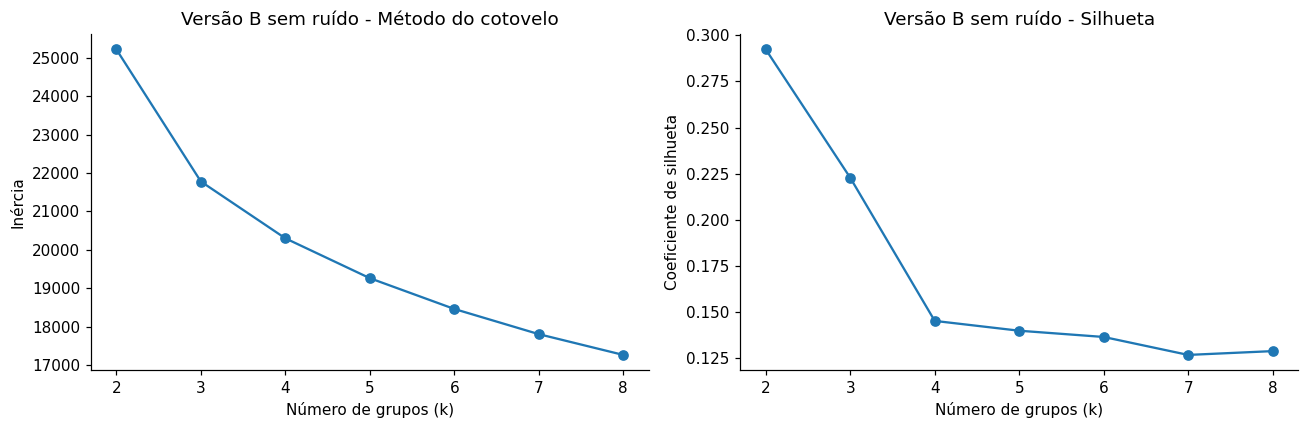

,k,silhueta_com_ruido,silhueta_sem_ruido
0,2,0.267898,0.292368
1,3,0.201986,0.222764
2,4,0.131940,0.145132
3,5,0.124102,0.139810
4,6,0.125141,0.136421
5,7,0.114730,0.126683
6,8,0.117227,0.128745


Compare as silhuetas e observe se os grupos e seus perfis ficaram mais separados.


In [14]:
# Atividade complementar A
# Repetir a avaliação da Tarefa 2.1 removendo os clientes marcados como ruído.
mascara_sem_ruido = ~df.loc[X_B.index, "DBSCAN_Ruido"].to_numpy()
X_B_sem_ruido = X_B.loc[mascara_sem_ruido].copy()
metricas_B_sem_ruido = avaliar_kmeans(X_B_sem_ruido, "Versão B sem ruído")

comparacao_silhueta = metricas_B[["k", "silhueta"]].merge(
    metricas_B_sem_ruido[["k", "silhueta"]],
    on="k", suffixes=("_com_ruido", "_sem_ruido")
)
display(comparacao_silhueta)
print("Compare as silhuetas e observe se os grupos e seus perfis ficaram mais separados.")


,k,inercia,silhueta
0,2,8001.780016,0.373694
1,3,6868.895350,0.277102
2,4,5897.347366,0.261992
3,5,5333.508150,0.264368
4,6,4862.769018,0.272517
5,7,4300.521015,0.273599
6,8,4057.869965,0.262742


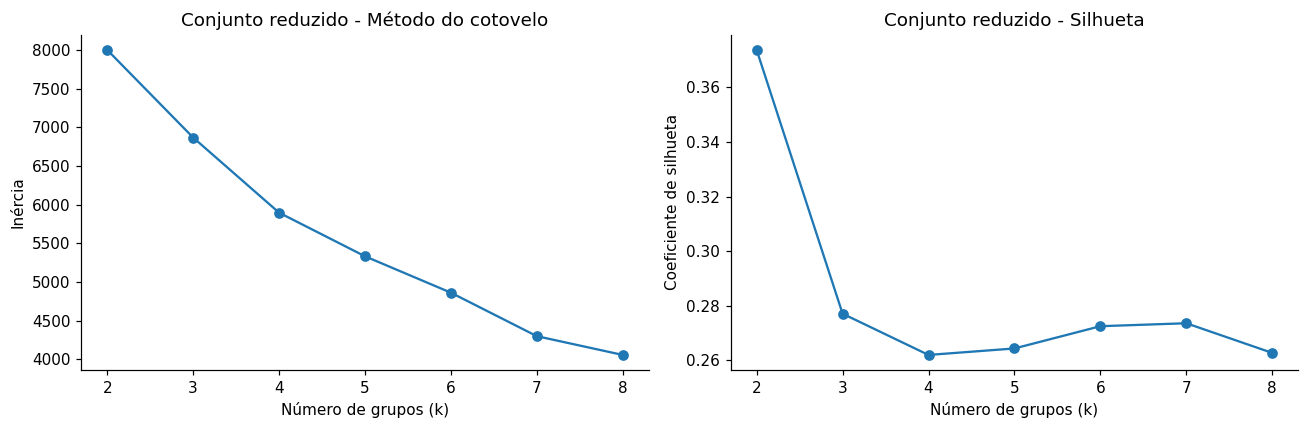

,k,silhueta_versao_B,silhueta_reduzido
0,2,0.267898,0.373694
1,3,0.201986,0.277102
2,4,0.131940,0.261992
3,5,0.124102,0.264368
4,6,0.125141,0.272517
5,7,0.114730,0.273599
6,8,0.117227,0.262742


O conjunto reduzido facilita a implantação por usar menos variáveis,
simplificando coleta, manutenção e interpretação, embora possa perder informação.


In [15]:
# Atividade complementar B
# Conjunto reduzido com seis variáveis derivadas e interpretáveis.
X_reduzido = pd.DataFrame(index=df.index)
X_reduzido["Renda"] = df["Income"].fillna(df["Income"].median())
X_reduzido["Idade"] = 2014 - df["Year_Birth"]
X_reduzido["Total_Filhos"] = df["Kidhome"] + df["Teenhome"]
X_reduzido["Gasto_Total"] = df[
    ["MntWines", "MntFruits", "MntMeatProducts",
     "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
].sum(axis=1)
X_reduzido["Total_Compras"] = df[
    ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
].sum(axis=1)
X_reduzido["Visitas_Site"] = df["NumWebVisitsMonth"]
X_reduzido = X_reduzido.replace([np.inf, -np.inf], np.nan)
X_reduzido = X_reduzido.fillna(X_reduzido.median())

metricas_reduzido = avaliar_kmeans(X_reduzido, "Conjunto reduzido")
comparacao_reduzido = metricas_B[["k", "silhueta"]].merge(
    metricas_reduzido[["k", "silhueta"]],
    on="k", suffixes=("_versao_B", "_reduzido")
)
display(comparacao_reduzido)
print("O conjunto reduzido facilita a implantação por usar menos variáveis,")
print("simplificando coleta, manutenção e interpretação, embora possa perder informação.")


In [16]:
# Atividade complementar C
# Ajustar K-Means com k=4 na versão B e reconstruir a tabela de perfil.
modelo_k4 = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=4, random_state=42, n_init=10)
)
segmentos_k4 = modelo_k4.fit_predict(X_B)
df["Segmento_k4"] = segmentos_k4

perfil_k4_base = df.copy()
perfil_k4_base["Idade"] = 2014 - perfil_k4_base["Year_Birth"]
perfil_k4_base["Total_Filhos"] = (
    perfil_k4_base["Kidhome"] + perfil_k4_base["Teenhome"]
)
perfil_k4_base["Gasto_Total"] = perfil_k4_base[
    ["MntWines", "MntFruits", "MntMeatProducts",
     "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
].sum(axis=1)

perfil_k4 = perfil_k4_base.groupby("Segmento_k4").agg(
    Renda_Media=("Income", "mean"),
    Idade_Media=("Idade", "mean"),
    Filhos_Medios=("Total_Filhos", "mean"),
    Gasto_Total_Medio=("Gasto_Total", "mean"),
    Gasto_Vinhos_Medio=("MntWines", "mean"),
    Compras_Site_Medias=("NumWebPurchases", "mean"),
    Compras_Catalogo_Medias=("NumCatalogPurchases", "mean"),
    Compras_Loja_Medias=("NumStorePurchases", "mean"),
    Visitas_Site_Medias=("NumWebVisitsMonth", "mean"),
    Numero_Clientes=("ID", "count")
).round(2)

display(perfil_k4)
print("Compare a tabela de quatro grupos com a tabela da Parte 3.")
print("A subdivisão mais útil será aquela que separar perfis antes misturados")
print("e que permita campanhas diferentes sem criar grupos pequenos ou semelhantes.")


,Renda_Media,Idade_Media,Filhos_Medios,Gasto_Total_Medio,Gasto_Vinhos_Medio,Compras_Site_Medias,Compras_Catalogo_Medias,Compras_Loja_Medias,Visitas_Site_Medias,Numero_Clientes
Segmento_k4,,,,,,,,,,
0,29467.96,35.92,0.88,100.01,33.23,2.24,0.51,3.13,6.96,585
1,58927.68,49.23,1.12,812.17,522.45,6.59,3.30,7.99,5.82,537
2,43480.36,50.89,1.67,129.07,73.95,2.35,0.76,3.63,5.79,531
3,76731.38,45.60,0.21,1352.32,581.86,5.20,5.94,8.39,2.79,587


Compare a tabela de quatro grupos com a tabela da Parte 3.
A subdivisão mais útil será aquela que separar perfis antes misturados
e que permita campanhas diferentes sem criar grupos pequenos ou semelhantes.
